# Bioresponse EDA

평가지표 **LogLoss** (낮을수록 좋음), 피처는 익명화된 `D1`~`D1776`.
도메인 해석이 불가능하므로 개별 피처가 아니라 **집계 중심**으로 본다.

전처리는 polars, 학습 직전에만 `.to_numpy()` — sklearn/LightGBM은 polars를 직접 먹지 못한다.

## 0. 로딩

In [1]:
%matplotlib inline
import logging
import matplotlib
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

for p in ('/System/Library/Fonts/AppleSDGothicNeo.ttc',):
    import os
    if os.path.exists(p):
        matplotlib.font_manager.fontManager.addfont(p)
        plt.rcParams['font.family'] = 'Apple SD Gothic Neo'
        break
plt.rcParams['axes.unicode_minus'] = False

DATA, OUT = 'data', 'EDA'
os.makedirs(OUT, exist_ok=True)

# 함정: polars 기본 스키마 추론은 앞 100행만 본다.
# D651은 앞부분이 전부 정수라 i64로 잡히고 뒤의 0.166666667에서 ComputeError가 난다.
# infer_schema_length=None 으로 전체를 스캔해야 Float64로 올바르게 잡힌다.
train = pl.read_csv(f'{DATA}/train.csv', infer_schema_length=None)
test = pl.read_csv(f'{DATA}/test.csv', infer_schema_length=None)

feats = [c for c in train.columns if c != 'Activity']
train.shape, test.shape, len(feats)

((3751, 1777), (2501, 1776), 1776)

## 1. 기본 정보 — shape / dtype / 결측

In [2]:
print(f'train : {train.shape}')
print(f'test  : {test.shape}')
print(f'피처  : {len(feats)}개 (D1~D{len(feats)})')
print(f'dtype : {sorted({str(d) for d in train.dtypes})}')

# 결측 — polars null_count는 컬럼별 1행 DataFrame을 돌려준다
n_tr = train.null_count().to_numpy().sum()
n_te = test.null_count().to_numpy().sum()
print(f'결측  : train {n_tr} / test {n_te}')

# 전체 값 범위
rng = train.select(
    pl.min_horizontal(pl.all().exclude('Activity').min()).alias('min'),
    pl.max_horizontal(pl.all().exclude('Activity').max()).alias('max'),
)
print(f'값 범위: {rng.row(0)}  → 이미 [0,1] 정규화. 스케일링 불필요')

train : (3751, 1777)
test  : (2501, 1776)
피처  : 1776개 (D1~D1776)
dtype : ['Float64', 'Int64']
결측  : train 0 / test 0
값 범위: (0.0, 1.0)  → 이미 [0,1] 정규화. 스케일링 불필요


## 2. 타깃 분포와 기준점

LogLoss는 **낮을수록** 좋다. Accuracy와 방향이 반대라는 점을 계속 의식해야 한다.
베이스라인이 아래 기준점보다 나쁘면 파이프라인 버그다.

In [3]:
dist = (train.group_by('Activity')
        .len()
        .with_columns((pl.col('len') / train.height).alias('ratio'))
        .sort('Activity'))
print(dist)

y = train['Activity'].to_numpy()
p = y.mean()

def logloss(prob):
    prob = np.clip(prob, 1e-15, 1 - 1e-15)
    return -(y * np.log(prob) + (1 - y) * np.log(1 - prob)).mean()

print(f'\nall-0.5 제출        : LogLoss {logloss(np.full_like(y, 0.5, dtype=float)):.4f}')
print(f'train 평균({p:.4f}) 제출 : LogLoss {logloss(np.full_like(y, p, dtype=float)):.4f}')
print(f'2012 LB 1위          : LogLoss 0.37355')

shape: (2, 3)
┌──────────┬──────┬──────────┐
│ Activity ┆ len  ┆ ratio    │
│ ---      ┆ ---  ┆ ---      │
│ i64      ┆ u32  ┆ f64      │
╞══════════╪══════╪══════════╡
│ 0        ┆ 1717 ┆ 0.457745 │
│ 1        ┆ 2034 ┆ 0.542255 │
└──────────┴──────┴──────────┘

all-0.5 제출        : LogLoss 0.6931
train 평균(0.5423) 제출 : LogLoss 0.6896
2012 LB 1위          : LogLoss 0.37355


## 3. 피처 타입 분포

1776개를 개별로 볼 수 없으니 고유값 개수로 분류한다.
`pl.all().n_unique()` 한 줄이면 전 컬럼 집계가 끝난다.

In [4]:
nuniq = (train.select(pl.all().exclude('Activity').n_unique())
         .to_numpy()[0])
nuniq = np.asarray(nuniq)

const = nuniq == 1
binary = nuniq == 2
cont = nuniq > 2
idx = np.arange(len(feats))

print(f'상수 (unique=1) : {const.sum()}개')
print(f'이진 (unique=2) : {binary.sum()}개')
print(f'연속 (unique>2) : {cont.sum()}개  (unique 중앙값 {int(np.median(nuniq[cont]))})')
print(f'연속 피처 위치  : D{idx[cont].min()+1} ~ D{idx[cont].max()+1}')
print(f'이진 피처 위치  : D{idx[binary].min()+1} ~ D{idx[binary].max()+1}  → 연속/이진이 구간으로 섞여 있다')

상수 (unique=1) : 0개
이진 (unique=2) : 835개
연속 (unique>2) : 941개  (unique 중앙값 8)
연속 피처 위치  : D1 ~ D951
이진 피처 위치  : D23 ~ D1776  → 연속/이진이 구간으로 섞여 있다


### 주의 — 'unique=2'가 전부 0/1은 아니다

하나는 `{0, 0.1667}`이다. "이진이니까 0/1"로 가정하고 캐스팅하면 값이 깨진다.

In [5]:
combos = {}
bin_feats = [feats[i] for i in idx[binary]]
uq = train.select([pl.col(c).unique().sort().implode().alias(c) for c in bin_feats])
for c in bin_feats:
    v = tuple(uq[c][0].to_list())
    combos.setdefault(v, []).append(c)

for v, cols in sorted(combos.items(), key=lambda x: -len(x[1])):
    print(f'{v} : {len(cols)}개' + ('' if len(cols) > 3 else f'  → {cols}'))

(0, 1) : 834개
(0.0, 0.166666667) : 1개  → ['D823']


## 4. 상수 / 중복 피처

제거 대상을 찾는다. 중복 탐지는 **transpose 후 행 중복**으로 보면 polars 한 줄이다
(전치하면 피처 하나가 행 하나가 되고, `is_duplicated()`가 전 컬럼 동일 행을 잡는다).

In [6]:
print(f'train 상수 피처 : {const.sum()}개')

# train+test를 합쳐도 상수인지 (제거 판단은 합친 기준이 맞다)
# 함정: 같은 컬럼이라도 train은 Int64 / test는 Float64로 추론되는 경우가 있어
# 그냥 concat하면 SchemaError가 난다. 양쪽을 Float64로 맞춘 뒤 합친다.
allrows = pl.concat([train.drop('Activity').cast(pl.Float64),
                     test.cast(pl.Float64)])
nuniq_all = np.asarray(allrows.select(pl.all().n_unique()).to_numpy()[0])
print(f'train+test 상수 : {(nuniq_all == 1).sum()}개')

# 완전 중복 피처: 전치 → 행 중복 판정
t = allrows.transpose(include_header=True, header_name='feature')
dup_mask = t.drop('feature').is_duplicated()
dups = t.filter(dup_mask)['feature'].to_list()
print(f'완전 중복 피처  : {len(dups)}개  {dups[:10]}')

train 상수 피처 : 0개


train+test 상수 : 0개
완전 중복 피처  : 0개  []


### near-constant

소수 클래스가 극소수인 피처는 사실상 상수다. 컬럼별 최빈값 빈도를 봐야 하는데
1776컬럼 × 6252행이면 numpy 쪽이 코드가 짧다.

In [7]:
both = allrows.to_numpy().astype(np.float64)
maxcnt = np.array([np.unique(both[:, i], return_counts=True)[1].max()
                   for i in range(both.shape[1])])
minor = len(both) - maxcnt   # 최빈값이 아닌 행 수

for th in (1, 2, 5, 10):
    print(f'소수값 {th:>2}개 이하 : {(minor <= th).sum()}개')
print(f'\n전체 {len(both)}행 기준 — 제거할 만한 near-constant는 사실상 없다')

소수값  1개 이하 : 2개
소수값  2개 이하 : 4개
소수값  5개 이하 : 9개
소수값 10개 이하 : 26개

전체 6252행 기준 — 제거할 만한 near-constant는 사실상 없다


## 5. 타깃과의 상관

`pl.corr`를 1776개 expression으로 한 번에 돌린다.

In [8]:
corr = (train.select([pl.corr(pl.col(c), pl.col('Activity')).alias(c) for c in feats])
        .to_numpy()[0])
corr = np.nan_to_num(np.asarray(corr, dtype=float))
order = np.argsort(corr)

print('상위 10 (양):')
for i in order[::-1][:10]:
    print(f'  {feats[i]:>7}  {corr[i]:+.4f}  unique={nuniq[i]}')
print('하위 10 (음):')
for i in order[:10]:
    print(f'  {feats[i]:>7}  {corr[i]:+.4f}  unique={nuniq[i]}')

print(f'\n|corr| 최대 {np.abs(corr).max():.4f} / 평균 {np.abs(corr).mean():.4f}')
print(f'|corr| > 0.1 : {(np.abs(corr) > 0.1).sum()}개')
print(f'|corr| > 0.2 : {(np.abs(corr) > 0.2).sum()}개')
print('\n→ D27 하나만 압도적이고 나머지는 약한 신호가 넓게 퍼져 있다.')
print('   소수 피처 선택보다 전부 쓰는 트리 앙상블이 맞는 구조.')

상위 10 (양):
      D27  +0.4723  unique=2
     D469  +0.2686  unique=10
     D182  +0.2287  unique=991
     D747  +0.2265  unique=8
     D659  +0.2260  unique=22
     D146  +0.2133  unique=36
     D607  +0.2103  unique=10
     D209  +0.2102  unique=932
     D660  +0.2049  unique=24
     D596  +0.2041  unique=7
하위 10 (음):
     D217  -0.2334  unique=554
      D87  -0.2231  unique=586
     D187  -0.1986  unique=571
     D158  -0.1977  unique=36
      D60  -0.1802  unique=90
      D61  -0.1746  unique=649
     D173  -0.1693  unique=1435
     D175  -0.1626  unique=1742
     D129  -0.1535  unique=14
     D103  -0.1519  unique=2980

|corr| 최대 0.4723 / 평균 0.0427
|corr| > 0.1 : 152개
|corr| > 0.2 : 12개

→ D27 하나만 압도적이고 나머지는 약한 신호가 넓게 퍼져 있다.
   소수 피처 선택보다 전부 쓰는 트리 앙상블이 맞는 구조.


## 6. 피처 간 상관 — 157만 쌍 전수

여기는 `Z.T @ Z` 행렬곱 한 번이면 끝나므로 numpy를 쓴다.
polars expression으로 1776² 쌍을 만들면 수백만 개 expression이 되어 비현실적이다.

In [9]:
Z = (both - both.mean(0)) / (both.std(0) + 1e-12)
C = (Z.T @ Z) / len(both)
iu = np.triu_indices(len(feats), 1)
cv = C[iu]

print(f'쌍 개수 : {len(cv):,}')
for th in (0.99, 0.95, 0.9, 0.8):
    print(f'  |r| > {th} : {(np.abs(cv) > th).sum():,} 쌍')

print('\n상위 5 쌍:')
for k in np.argsort(np.abs(cv))[::-1][:5]:
    print(f'  {feats[iu[0][k]]:>7} ~ {feats[iu[1][k]]:<7} r={cv[k]:+.4f}')

print(f'\n|r| 최댓값 {np.abs(cv).max():.4f}')
print('→ 0.9를 넘는 쌍이 정확히 0개. 자연 데이터에서 이렇게 딱 잘리지 않는다.')
print('   주최측이 r>0.9 피처를 미리 제거해둔 것으로 보인다 → 중복 제거할 게 없다.')

쌍 개수 : 1,576,200
  |r| > 0.99 : 0 쌍
  |r| > 0.95 : 0 쌍
  |r| > 0.9 : 0 쌍
  |r| > 0.8 : 454 쌍

상위 5 쌍:


     D515 ~ D810    r=+0.8999
     D869 ~ D870    r=+0.8998
     D478 ~ D758    r=+0.8997
     D519 ~ D815    r=+0.8990
     D195 ~ D203    r=+0.8990

|r| 최댓값 0.8999
→ 0.9를 넘는 쌍이 정확히 0개. 자연 데이터에서 이렇게 딱 잘리지 않는다.
   주최측이 r>0.9 피처를 미리 제거해둔 것으로 보인다 → 중복 제거할 게 없다.


## 7. train vs test 분포 차이

In [10]:
X = train.select(feats).to_numpy().astype(np.float64)
Xt = test.select(feats).to_numpy().astype(np.float64)
gap = np.abs(X.mean(0) - Xt.mean(0)) / (X.std(0) + 1e-9)

for i in np.argsort(gap)[::-1][:8]:
    print(f'{feats[i]:>7}  표준화 평균차 {gap[i]:.3f}  '
          f'(train {X[:, i].mean():.4f} / test {Xt[:, i].mean():.4f})')
print('\n→ 유의미한 shift 없음. CV를 믿어도 된다.')

   D823  표준화 평균차 0.278  (train 0.0000 / test 0.0008)
   D302  표준화 평균차 0.149  (train 0.0002 / test 0.0010)
   D801  표준화 평균차 0.094  (train 0.0002 / test 0.0006)
   D437  표준화 평균차 0.090  (train 0.0015 / test 0.0033)
   D347  표준화 평균차 0.089  (train 0.0038 / test 0.0064)
   D634  표준화 평균차 0.086  (train 0.0008 / test 0.0018)
   D228  표준화 평균차 0.083  (train 0.0211 / test 0.0269)
   D772  표준화 평균차 0.079  (train 0.0028 / test 0.0045)

→ 유의미한 shift 없음. CV를 믿어도 된다.


## 8. 차트

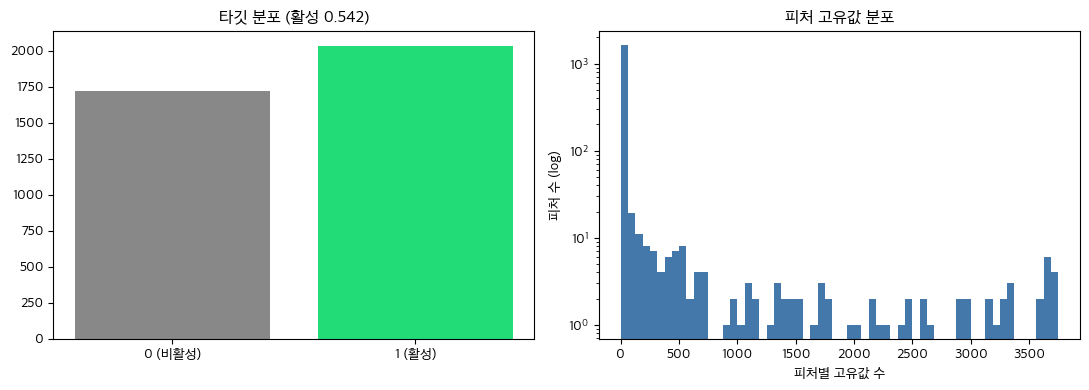

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(['0 (비활성)', '1 (활성)'], [int((1 - y).sum()), int(y.sum())], color=['#888', '#2d7'])
ax[0].set_title(f'타깃 분포 (활성 {y.mean():.3f})')
ax[1].hist(nuniq, bins=60, color='#47a'); ax[1].set_yscale('log')
ax[1].set_xlabel('피처별 고유값 수'); ax[1].set_ylabel('피처 수 (log)')
ax[1].set_title('피처 고유값 분포')
plt.tight_layout(); plt.savefig(f'{OUT}/eda_01_target_and_types.png', dpi=110); plt.show()

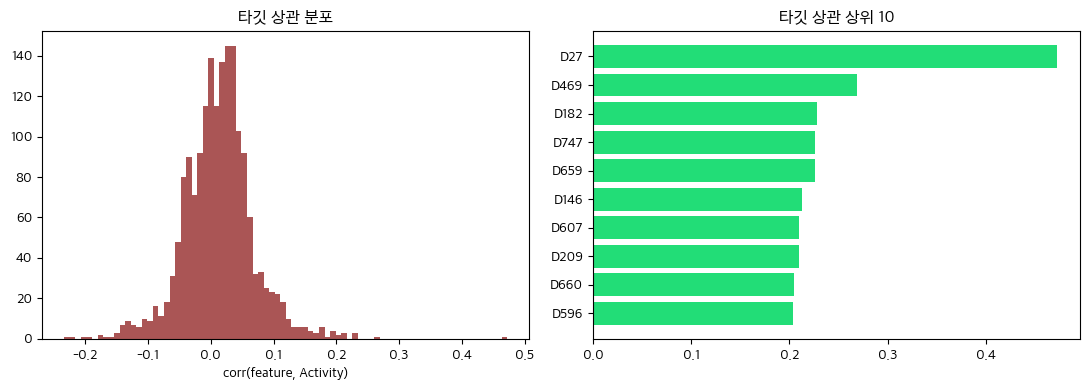

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(corr, bins=80, color='#a55')
ax[0].set_title('타깃 상관 분포'); ax[0].set_xlabel('corr(feature, Activity)')
top = order[::-1][:10]
ax[1].barh([feats[i] for i in top][::-1], [corr[i] for i in top][::-1], color='#2d7')
ax[1].set_title('타깃 상관 상위 10')
plt.tight_layout(); plt.savefig(f'{OUT}/eda_02_target_corr.png', dpi=110); plt.show()

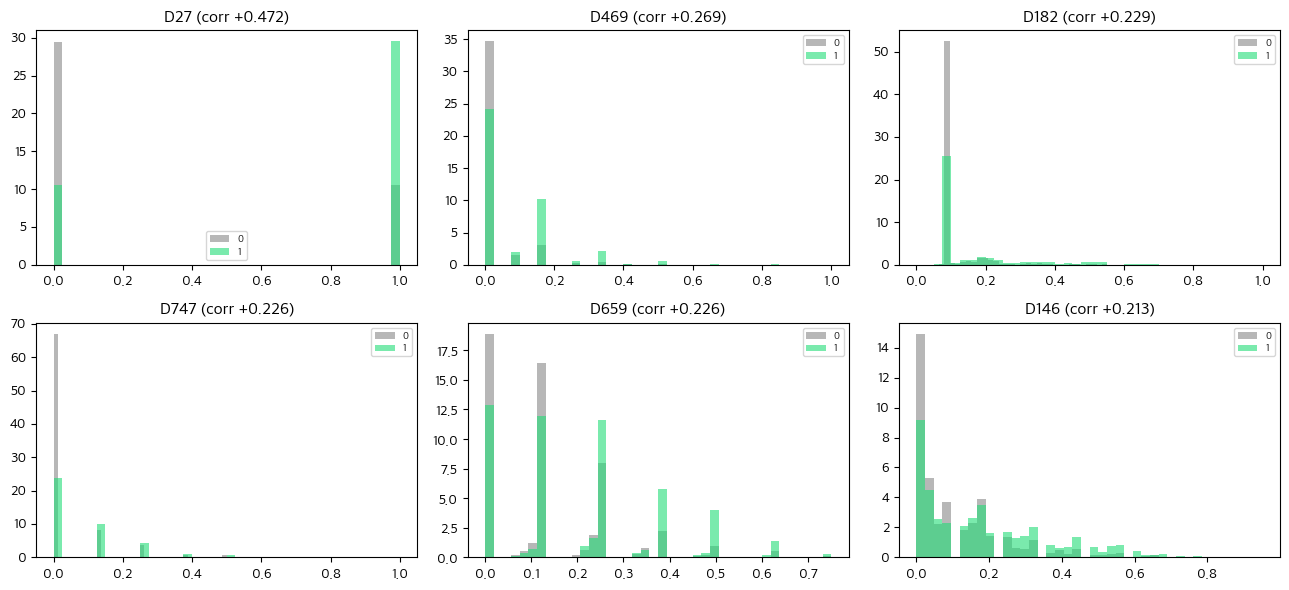

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for a, i in zip(axes.ravel(), order[::-1][:6]):
    a.hist(X[y == 0, i], bins=40, alpha=.6, label='0', color='#888', density=True)
    a.hist(X[y == 1, i], bins=40, alpha=.6, label='1', color='#2d7', density=True)
    a.set_title(f'{feats[i]} (corr {corr[i]:+.3f})'); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUT}/eda_03_top6_by_class.png', dpi=110); plt.show()

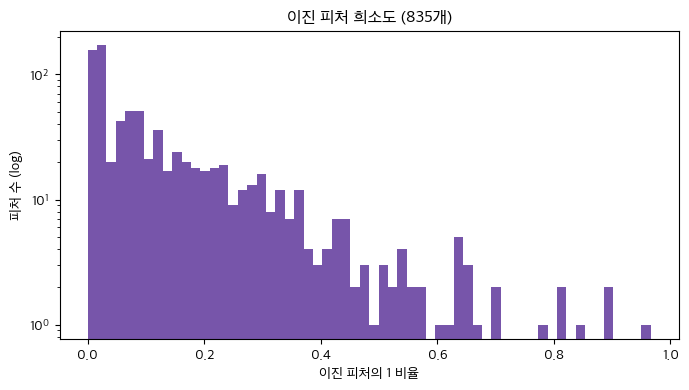

1 비율 중앙값 0.0736 / 1% 미만 피처 7개


In [14]:
rate = X[:, binary].mean(0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(rate, bins=60, color='#75a'); ax.set_yscale('log')
ax.set_xlabel('이진 피처의 1 비율'); ax.set_ylabel('피처 수 (log)')
ax.set_title(f'이진 피처 희소도 ({binary.sum()}개)')
plt.tight_layout(); plt.savefig(f'{OUT}/eda_04_binary_sparsity.png', dpi=110); plt.show()
print(f'1 비율 중앙값 {np.median(rate):.4f} / 1% 미만 피처 {(rate < 0.01).sum()}개')

## 결론 — 베이스라인 설계

| 관찰 | 결정 |
|---|---|
| 결측 0, 전 피처 [0,1] | 전처리 불필요 |
| 상수 0 / 완전중복 0 / near-constant 0 | **피처 제거 없이 1776개 전부 사용** |
| |r|>0.9 쌍 0개 (주최측 사전 제거) | 상관 기반 제거도 불필요 |
| 약한 신호가 넓게 분산 (|r|>0.2가 12개뿐) | 피처 선택보다 트리 앙상블 |
| 희소 이진 835개 + 연속 941개 | **LightGBM** (희소 처리 + 1776컬럼에서 RF보다 빠름) |
| 타깃 54:46 | StratifiedKFold 5-fold |
| 지표 LogLoss | `predict_proba`, `scoring='neg_log_loss'` |

기준점: all-0.5 = 0.6931 / train평균 = 0.6896 / 2012 LB 1위 = 0.37355